# I-01: fresh Run All

Start from the beginning with the repaired direct/nonthinking workflow.
Attach **only the matching i01-source.zip**, choose **GPU T4 ×2**, enable
**Internet**, fill in the two actual session facts in the first cell, then
**Run All**. No course-2/course-3 checkpoint or result is needed.

This notebook runs setup → self-check → weights → both resident workers → six
state checks → twelve new direct controls → two headroom probes → report and
verified downloadable checkpoint. **At most 20 first model attempts**, plus
eligible bounded infrastructure retries, within this new study's 500-attempt
limit. Wrong mathematical answers are measured; valid protocol is required.
Thinking inference, pilots, freeze and main experiments are separate stages.

Ordinary cells show each stage and can be rerun individually. Saved outcomes
are never resampled. A refusal preserves evidence and blocks generation at the
failed prerequisite; inspect the receipt before retrying. Models stay resident
after successful completion. Stop Kaggle when finished to release the allocation.


## 1. Set the session facts once

Read the actual remaining session time and GPU allowance from Kaggle now. Enter the remaining session minutes and a short truthful allowance note. These are provider facts, not experiment settings; no quota or deadline is guessed. RUN_DIR needs changing only for a separate new study.


In [1]:
RUN_DIR = "/kaggle/working/i01-fresh-study"
SESSION_REMAINING_MINUTES = 700  # Replace with the minutes actually remaining now.
SESSION_ALLOWANCE_EVIDENCE = "lorem"  # Describe the current allowance shown by Kaggle.


## 2. Inspect the workspace

Select and verify the small source attachment. Inventory only; no installation or inference.


In [2]:
from pathlib import Path
import hashlib, json, shutil, sys, tempfile, zipfile

# Select one exact small source attachment. ZIP and Kaggle-expanded roots work.
SOURCE_BUNDLE = None  # Set only if more than one candidate is attached.
source_candidates = list(Path('/kaggle/input').rglob('i01-source.zip'))
source_candidates += [p.parent for p in Path('/kaggle/input').rglob('source-release.json')]
# Expanded old checkpoints carry their own historical source. They are evidence,
# not candidates for this repaired notebook's active source attachment.
def repaired_source_manifest(path):
    try:
        if path.is_dir():
            manifest = json.loads((path/'source-release.json').read_text())
        else:
            with zipfile.ZipFile(path) as archive:
                manifest = json.loads(archive.read('source-release.json'))
        return manifest if all('recovery/i01/'+name+'.py' in manifest['files'] for name in ('policy','continuation')) else None
    except (OSError, ValueError, KeyError, zipfile.BadZipFile):
        return None
unique_sources = {}
for candidate in source_candidates:
    manifest = repaired_source_manifest(candidate)
    if manifest:
        identity = (manifest.get('git_head'), json.dumps(manifest['files'], sort_keys=True))
        unique_sources.setdefault(identity, candidate)  # Same ZIP/expanded release is one choice.
source_candidates = list(unique_sources.values())
if SOURCE_BUNDLE is None:
    if len(source_candidates) != 1:
        raise RuntimeError(f'Select SOURCE_BUNDLE explicitly; candidates: {source_candidates}')
    SOURCE_BUNDLE = source_candidates[0]
selected_source = Path(SOURCE_BUNDLE)
with tempfile.TemporaryDirectory(prefix='i01-source-', dir='/kaggle/working') as staging_name:
    staging = Path(staging_name)
    if selected_source.is_file():
        with zipfile.ZipFile(selected_source) as source_zip:
            infos = source_zip.infolist()
            if sum(p.file_size for p in infos) > 64 * 2**20 or len({p.filename for p in infos}) != len(infos):
                raise RuntimeError('Source attachment size or duplicate member violation')
            for item in infos:
                p = Path(item.filename)
                if p.is_absolute() or '..' in p.parts or '\\' in item.filename or ':' in item.filename or ((item.external_attr >> 16) & 0o170000) == 0o120000:
                    raise RuntimeError('Unsafe source archive member')
            if source_zip.testzip() is not None:
                raise RuntimeError('Source ZIP integrity failed')
            source_zip.extractall(staging)
    elif selected_source.is_dir():
        if any(p.is_symlink() for p in selected_source.rglob('*')):
            raise RuntimeError('Select an ordinary verified expanded source directory')
        shutil.copytree(selected_source, staging, dirs_exist_ok=True)
    else:
        raise RuntimeError('Missing exact selected source attachment')
    release = json.loads((staging/'source-release.json').read_text())
    if release['format'] != 'i01-online-source-v1':
        raise RuntimeError('Wrong source release format')
    if not all('recovery/i01/'+name+'.py' in release['files'] for name in ('policy','continuation')):
        raise RuntimeError('This notebook requires the repaired direct-protocol source packet; preserve old checkpoints and replace the active source attachment.')
    head = release.get('git_head', '')
    if len(head) != 40 or any(c not in '0123456789abcdef' for c in head):
        raise RuntimeError('Invalid source release commit')
    source_root = Path('/kaggle/working') / ('i01-source-' + head[:12])
    for relative, wanted in release['files'].items():
        path = staging/relative
        if not path.is_file() or path.stat().st_size != wanted['bytes'] or hashlib.sha256(path.read_bytes()).hexdigest() != wanted['sha256']:
            raise RuntimeError(f'Source identity failed: {relative}')
        if source_root.exists() and (not (source_root/relative).is_file() or hashlib.sha256((source_root/relative).read_bytes()).hexdigest() != wanted['sha256']):
            raise RuntimeError('Existing source differs; select a fresh session/source directory')
    if not source_root.exists():
        shutil.copytree(staging, source_root)
loaded_source = sys.modules.get('recovery')
if loaded_source is not None and not Path(loaded_source.__file__).resolve().is_relative_to(source_root.resolve()):
    raise RuntimeError('Restart the notebook kernel before using this source release; saved study files are preserved.')
sys.path.insert(0, str(source_root))
from recovery.i01.notebook import Study
if 'study' not in globals():
    study = Study(source_root, run=RUN_DIR)
elif study.source.resolve()!=source_root.resolve() or study.run_dir.resolve()!=Path(RUN_DIR).resolve():
    raise RuntimeError('Finish the current study and restart the kernel before changing source or RUN_DIR; existing study files are preserved.')
study.bootstrap_status()


Workspace,Observed value
Python,"3.13.15 (main, Aug 6 2026, 11:06:22) [GCC 13.3.0]"
System,Linux
Source,/kaggle/working/i01-source-e17868e68569
Study files,/kaggle/working/i01-fresh-study


Device,Model,UUID,Memory (MiB)
0,Tesla T4,GPU-af70a816-5baf-1088-aae2-7d5642fe3459,15360
1,Tesla T4,GPU-d7340205-17ed-377c-bff1-a1e59cd35dcf,15360


Storage,Path,Free GiB
scratch,/kaggle/temp/i01,1069.91
working,/kaggle/working,19.5


Session window: unset; preparation is available, model loading requires actual facts in its dedicated cell.
Next: run Install the pinned runtime. Host acceptance still occurs before installation.


## 3. Record the fixed deadline

Record the observation BEFORE installation/downloads. Their elapsed time counts against this deadline. Rerunning this cell keeps the same deadline; use an explicit fresh observation to refresh it.


In [3]:
study.configure_session(remaining_minutes=SESSION_REMAINING_MINUTES,
    evidence=SESSION_ALLOWANCE_EVIDENCE);


Measurement,Recorded value
Deadline,2026-10-16T01:57:01.134871+00:00
Evidence,lorem
Apply after initialization,Yes


## 4. Install the pinned runtime

Create the isolated environment without ensurepip. Verified pip bootstrap, pinned dependencies, project installation and import checks have visible progress/logs. The controller uses an isolated headless environment.


In [4]:
study.install_runtime();


Setup: venv
Setup: download verified pip bootstrap wheel
Setup: bootstrap-pip
Setup: pip-isolation
Setup: dependencies
dependencies: 15s elapsed;      ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 156.9 MB/s  0:00:03
dependencies: 30s elapsed;      ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 183.7 MB/s  0:00:01
dependencies: 45s elapsed;   Downloading orjson-3.13.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (130 kB)
dependencies: 60s elapsed;   Downloading torch-2.11.0%2Bcu128-cp313-cp313-manylinux_2_28_x86_64.whl (820.3 MB)
dependencies: 75s elapsed;   Downloading pillow-12.1.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (7.0 MB)
dependencies: 90s elapsed; py, anyio, rich, requests-toolbelt, pydantic, nvidia-cusolver-cu12, matplotlib, httpx2, httpx, typer, langsmith, torch, langchain-core, huggingface-hub, tokenizers, langgraph-sdk, langgraph-checkpoint, bitsandbytes, accelerate, transformers, langgraph-prebuilt, langgraph-checkpoi

Measurement,Recorded value
Interpreter,/kaggle/temp/i01/i01-venv-e17868e68569/bin/python
Source,/kaggle/working/i01-source-e17868e68569
Scratch,/kaggle/temp/i01
Working,/kaggle/working
Hf cache,/kaggle/temp/i01/hf-cache
Setup seconds,185.82963188400004
Model attempts,0


## 5. Start the new study

Explicit independent rerun: new study ID, zero prior attempts, no checkpoint import and no previous result reuse. Repeating this cell in the same destination retains its existing calls and budget. A different existing campaign is refused.


In [5]:
study.start_new();


Measurement,Recorded value
Deadline,2026-10-16T01:57:01.134871+00:00
Evidence,lorem
Apply after initialization,Yes


session: recorded in the stage receipt
Checkpoint action/window: 1,421,303 bytes; integrity passed
window: complete · checkpoint /kaggle/working/i01-fresh-study/exports/latest.zip
Checkpoint study-open: 1,421,360 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-fresh-study/exports/latest.zip


Measurement,Recorded value
Attempt scope,independent-study
Attempts,0
Attempts unknown generated tokens,0
Attempts unknown ready seconds,0
Campaign attempts,0
Campaign attempts unknown ready seconds,0
Campaign generated tokens observed,0
Campaign ready seconds observed,0
Clear minus retain,Unknown / not recorded
Complete case descriptive mean,Unknown / not recorded


Main coverage,Value
Known paired outcomes,0 / 20
Campaign physical attempts,0 / 500 (0 here)
Clear minus retain,Unknown / not recorded
Unknown-outcome bounds,"[-1.0, 1.0]"


Logical slot,Resident,Load receipt
0,No,Not recorded
1,No,Not recorded


Budget,Value
attempt scope,independent-study
attempts,0
campaign attempts,0
contingency,0
in flight,0
local contingency,0
lost spending,"{'resolved': True, 'upper': 0}"
missing prior studies,[]
prior attempts,0
prior spending pending,Unknown / not recorded


## 6. Check implementation and tokenizer

Lightweight scripted mathematics, private views, persistence, accounting and archive checks, plus the native tokenizer. Zero model generations.


In [6]:
study.check_implementation();


Checkpoint action/selfcheck: 1,433,219 bytes; integrity passed
selfcheck: complete · checkpoint /kaggle/working/i01-fresh-study/exports/latest.zip


Measurement,Recorded value
Environment,scripted temporary DBs; no model loaded
Executed at,2026-10-15T14:20:22.779414+00:00
Model attempts,0
Native tokenizer,Yes
Passed,Yes


Lightweight check,State
native fixture 827/revised 780; duplicates/negative/boundary,Passed
fixed strata/seeds; private views; finality/wait; literal siblings; invalid actions,Passed
raw-before-effects; idempotence; pre-persistence retry; 499/500; backup/ZIP/expanded restore; unknown vs zero,Passed


Native tokenizer: passed


Checkpoint: passed


## 7. Download verified weights

Download/reuse the pinned model snapshot in scratch and verify its native files. No model inference.


In [7]:
study.download_weights();


Setup: weights-command
weights-command: 15s elapsed; Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
weights-command: 90s elapsed; Fetching 12 files:  50%|█████     | 6/12 [01:15<01:15, 12.67s/it]
weights-command: 105s elapsed; Verifying pinned native bytes 4/12: model.safetensors-00001-of-00004.safetensors (5,276,436,216 bytes)
weights-command: 120s elapsed; Verifying pinned native bytes 5/12: model.safetensors-00002-of-00004.safetensors (5,335,161,512 bytes)
weights-command: 135s elapsed; Verifying pinned native bytes 5/12: model.safetensors-00002-of-00004.safetensors (5,335,161,512 bytes)
weights-command: 150s elapsed; Verifying pinned native bytes 6/12: model.safetensors-00003-of-00004.safetensors (5,368,717,440 bytes)
weights-command: 165s elapsed; Verifying pinned native bytes 7/12: model.safetensors-00004-of-00004.safetensors (3,325,9

Measurement,Recorded value
Model,Qwen/Qwen3.5-9B
Revision,c202236235762e1c871ad0ccb60c8ee5ba337b9a
Snapshot,/kaggle/temp/i01/hf-cache/models--Qwen--Qwen3.5-9B/snapshots/c202236235762e1c871ad0ccb60c8ee5ba337b9a
Native total bytes,19329302519
Weights,Yes
Model attempts,0


## 8. Load both workers

Load the pinned replicas once, one per T4. Actual inventory, current session deadline and fresh-state accounting must pass. Loading does not generate a reply.


In [8]:
study.load_models();


Working · 60s · Loading weights:  73%|███████▎  | 312/427 [00:45<00:22,  5.14it/s]
Working · 75s · Model load: audit actual tensors, quantization and loading diagnostics
Working · 105s · Loading weights:  73%|███████▎  | 313/427 [00:20<00:17,  6.41it/s]
Checkpoint action/load: 1,493,942 bytes; integrity passed
load: complete · checkpoint /kaggle/working/i01-fresh-study/exports/latest.zip


Logical slot,CUDA UUID,Load seconds,Total device GiB
0,af70a816-5baf-1088-aae2-7d5642fe3459,73.07511505100001,14.56
1,d7340205-17ed-377c-bff1-a1e59cd35dcf,37.85757823300003,14.56


Logical slot,Model / revision,Attention,Recurrent fast path
0,Qwen/Qwen3.5-9B / c202236235762e1c871ad0ccb60c8ee5ba337b9a,recovery_t4_sdpa,No
1,Qwen/Qwen3.5-9B / c202236235762e1c871ad0ccb60c8ee5ba337b9a,recovery_t4_sdpa,No


Pinned text-only NF4/FP16 replicas accepted by the reviewed loader. The loading-only generation profile is not the per-call I-01 profile: direct uses 512 output tokens, temperature 0.7/top-p 0.8/top-k 20.
Known upstream documentation/deprecation messages and optional recurrent-kernel fallback are retained in controller-stderr.log. Full load/tensor inventories remain in sessions.csv and the checkpoint; no runtime upgrade is applied.
Checkpoint: passed


## 9. Check fresh-state readiness

Six A/B/A checks, three per worker. Real numerical/cache/provider defects block. Unequal A/B/A needs trace-based human review before proceeding; no automatic waiver or extra samples.


In [9]:
study.check_readiness();


hardware/state-0-A1 · GPU slot 0 · attempt 1 · campaign 1/500 (1 here)
Raw saved: hardware/state-0-A1 · 14 tokens · 3.7172916260000193 ready-model seconds
hardware/state-0-B · GPU slot 0 · attempt 2 · campaign 2/500 (2 here)
Raw saved: hardware/state-0-B · 16 tokens · 2.0932581190000974 ready-model seconds
hardware/state-0-A2 · GPU slot 0 · attempt 3 · campaign 3/500 (3 here)
Raw saved: hardware/state-0-A2 · 14 tokens · 1.6385518419999698 ready-model seconds
hardware/state-1-A1 · GPU slot 1 · attempt 1 · campaign 4/500 (4 here)
Raw saved: hardware/state-1-A1 · 14 tokens · 2.736546970000063 ready-model seconds
hardware/state-1-B · GPU slot 1 · attempt 2 · campaign 5/500 (5 here)
Raw saved: hardware/state-1-B · 16 tokens · 2.113929334999966 ready-model seconds
hardware/state-1-A2 · GPU slot 1 · attempt 3 · campaign 6/500 (6 here)
Raw saved: hardware/state-1-A2 · 14 tokens · 1.630995031999987 ready-model seconds
Working · 15s · Inference pid=382 device=1 seed=9113091594724103221 phase=dec

Measurement,Recorded value
Equality policy,Diagnostic: unexpected differences require explicit state-isolation review before qualification; no extra samples or decoding changes.
Needs review,No
Passed,Yes


Slot,Probe,Raw visible reply,Finite score steps,Fresh cache
0,A1,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
0,B,"{""message"":null,""submit"":100,""wait"":false}",16,Yes
0,A2,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
1,A1,"{""message"":null,""submit"":3,""wait"":false}",14,Yes
1,B,"{""message"":null,""submit"":100,""wait"":false}",16,Yes
1,A2,"{""message"":null,""submit"":3,""wait"":false}",14,Yes


A/B/A equal by slot: [True, True]; Diagnostic: unexpected differences require explicit state-isolation review before qualification; no extra samples or decoding changes.


Checkpoint: passed


## 10. Run direct protocol qualification

Twelve fresh original/revised full-information controls. All twelve must be committed, valid JSON and legal protocol. Accuracy is diagnostic; a wrong answer alone does not reject the model. Completed replies are reused on cell rerun.


In [10]:
study.qualify_direct();


qualification-00/control-original-direct · GPU slot 0 · attempt 4 · campaign 7/500 (7 here)
Raw saved: qualification-00/control-original-direct · 16 tokens · 2.4455455919999167 ready-model seconds
qualification-00/control-revised-direct · GPU slot 0 · attempt 5 · campaign 8/500 (8 here)
Raw saved: qualification-00/control-revised-direct · 16 tokens · 2.0329183000000057 ready-model seconds
qualification-01/control-original-direct · GPU slot 1 · attempt 4 · campaign 9/500 (9 here)
Raw saved: qualification-01/control-original-direct · 16 tokens · 2.618718938999905 ready-model seconds
qualification-01/control-revised-direct · GPU slot 1 · attempt 5 · campaign 10/500 (10 here)
Raw saved: qualification-01/control-revised-direct · 16 tokens · 2.057070885999906 ready-model seconds
qualification-02/control-original-direct · GPU slot 0 · attempt 6 · campaign 11/500 (11 here)
Raw saved: qualification-02/control-original-direct · 17 tokens · 2.659846729000037 ready-model seconds
qualification-02/c

Measurement,Recorded value
Admitted,12
Attempts unknown effort,0
Committed,12
Correct,10
Generated tokens observed,193
Mode,direct
Passed,Yes
Physical attempts,12
Planned,12
Policy,i01-direct-protocol-2026-10-15


Protocol qualification: 12/12 committed; 0 invalid actions; current eligible: True. Mathematical diagnostic: 10/12.
Original saved gate decision (unchanged): True; rule i01-direct-protocol-2026-10-15


Failed call,Truth,Submission,Error
qualification-03/control-original-direct,951,788,wrong scalar
qualification-03/control-revised-direct,920,788,wrong scalar


Checkpoint: passed


## 11. Inspect every direct control

Read-only truth/submission, correctness, validity, cost and failure-first raw inspection. Complete traces and raw replies are in the report/checkpoint. No thinking generation.


In [11]:
study.inspect_qualification(mode="direct");


Mode,Committed/planned,Correct,Wrong scalar,Invalid,Unexecuted,Current eligible,Historical passed
direct,12/12,10,2,0,0,Yes,Yes


Call,Truth,Submission,Valid,Correct,Error,Tokens,Ready seconds
qualification-00/control-original-direct,950,950,Yes,1,Unknown / not recorded,16,2.4455455919999167
qualification-00/control-revised-direct,921,921,Yes,1,Unknown / not recorded,16,2.0329183000000057
qualification-01/control-original-direct,999,999,Yes,1,Unknown / not recorded,16,2.618718938999905
qualification-01/control-revised-direct,931,931,Yes,1,Unknown / not recorded,16,2.057070885999906
qualification-02/control-original-direct,1000,1000,Yes,1,Unknown / not recorded,17,2.659846729000037
qualification-02/control-revised-direct,981,981,Yes,1,Unknown / not recorded,16,2.01688650899996
qualification-03/control-original-direct,951,788,Yes,0,Unknown / not recorded,16,2.1688165639999397
qualification-03/control-revised-direct,920,788,Yes,0,Unknown / not recorded,16,2.070708556999989
qualification-04/control-original-direct,956,956,Yes,1,Unknown / not recorded,16,2.3112593890000426
qualification-04/control-revised-direct,918,918,Yes,1,Unknown / not recorded,16,1.9792504280000003


Main paired coverage: 0/20 intended worlds. Campaign: 18/500 physical attempts (18 here, 0 prior); contingency including prior charges/gaps: 0/28. Historical 45 remain separate.


Admission resource,Value
Remaining attempt allowance,482
Contingency including bounded lost spending,0
Lost spending evidence,"{'resolved': True, 'upper': 0}"
Remaining session seconds,41463.600977


Showing 3/12 detailed call audits. Complete prompts/replies/tokens remain in conversations.html/.txt/.jsonl. Use study.inspect(..., audit_limit=None) to display all calls.


## 12. Check full headroom

Two full-input/full-output probes, one per current replica. Require at least 1.5 GiB measured free memory on both T4s. Success starts no pilot or main work.


In [12]:
study.check_headroom();


hardware/envelope-direct-0 · GPU slot 0 · attempt 10 · campaign 19/500 (19 here)
Working · 15s · Inference pid=368 device=0 seed=3554240822569505675 phase=decode elapsed=13.7s input=8192/8192 decode=0/512 peak_reserved_mib=7824.0
Working · 30s · Inference pid=368 device=0 seed=3554240822569505675 phase=decode elapsed=28.8s input=8192/8192 decode=145/512 peak_reserved_mib=7824.0
Working · 45s · Inference pid=368 device=0 seed=3554240822569505675 phase=decode elapsed=43.8s input=8192/8192 decode=292/512 peak_reserved_mib=7824.0
Working · 60s · Inference pid=368 device=0 seed=3554240822569505675 phase=decode elapsed=58.9s input=8192/8192 decode=440/512 peak_reserved_mib=7824.0
Raw saved: hardware/envelope-direct-0 · 512 tokens · 66.11761475499998 ready-model seconds
hardware/envelope-direct-1 · GPU slot 1 · attempt 10 · campaign 20/500 (20 here)
Working · 75s · Inference pid=382 device=1 seed=6895241862355992459 phase=prefill elapsed=0.0s input=0/8192 decode=0/512 peak_reserved_mib=7540.0

Measurement,Recorded value
Mode,direct
Passed,Yes
Reload,No
Session,227616c0-8f28-4b34-ab9c-cc53314c6cb4


Slot,Generated tokens,Observed free headroom (GiB),Failure
0,512,6.788,None recorded
1,512,6.784,None recorded


Checkpoint: passed


## 13. Build the report

Export qualification, failures, resources, all raw traces, tables and figures. All twenty main worlds stay explicitly unknown until their experiments are executed. Report generation keeps models resident.


Checkpoint action/report: 1,595,734 bytes; integrity passed
report: complete · checkpoint /kaggle/working/i01-fresh-study/exports/latest.zip


Measurement,Recorded value
Attempt scope,independent-study
Attempts,20
Attempts unknown generated tokens,0
Attempts unknown ready seconds,0
Campaign attempts,20
Campaign attempts unknown ready seconds,0
Campaign generated tokens observed,1305
Campaign ready seconds observed,171.31343735799976
Clear minus retain,Unknown / not recorded
Complete case descriptive mean,Unknown / not recorded


Main coverage,Value
Known paired outcomes,0 / 20
Campaign physical attempts,20 / 500 (20 here)
Clear minus retain,Unknown / not recorded
Unknown-outcome bounds,"[-1.0, 1.0]"


Checkpoint: passed


Paired outcome,Worlds
unknown,20


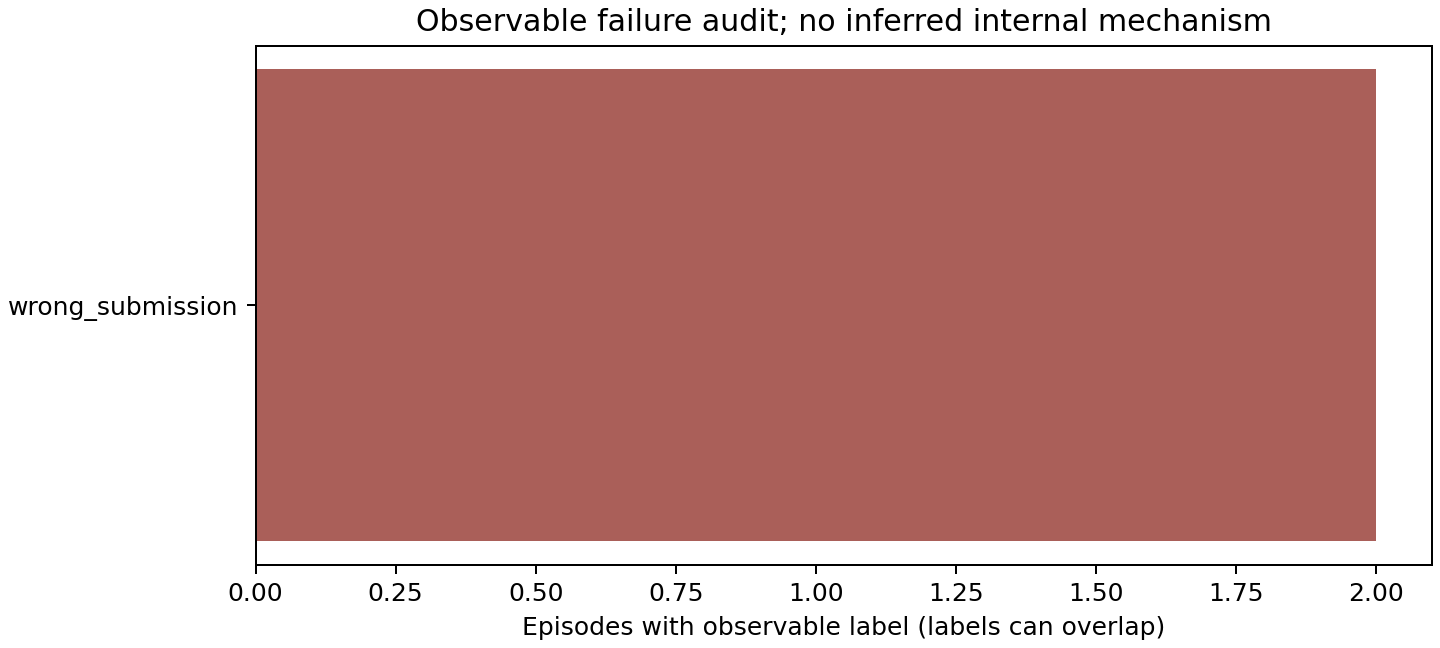

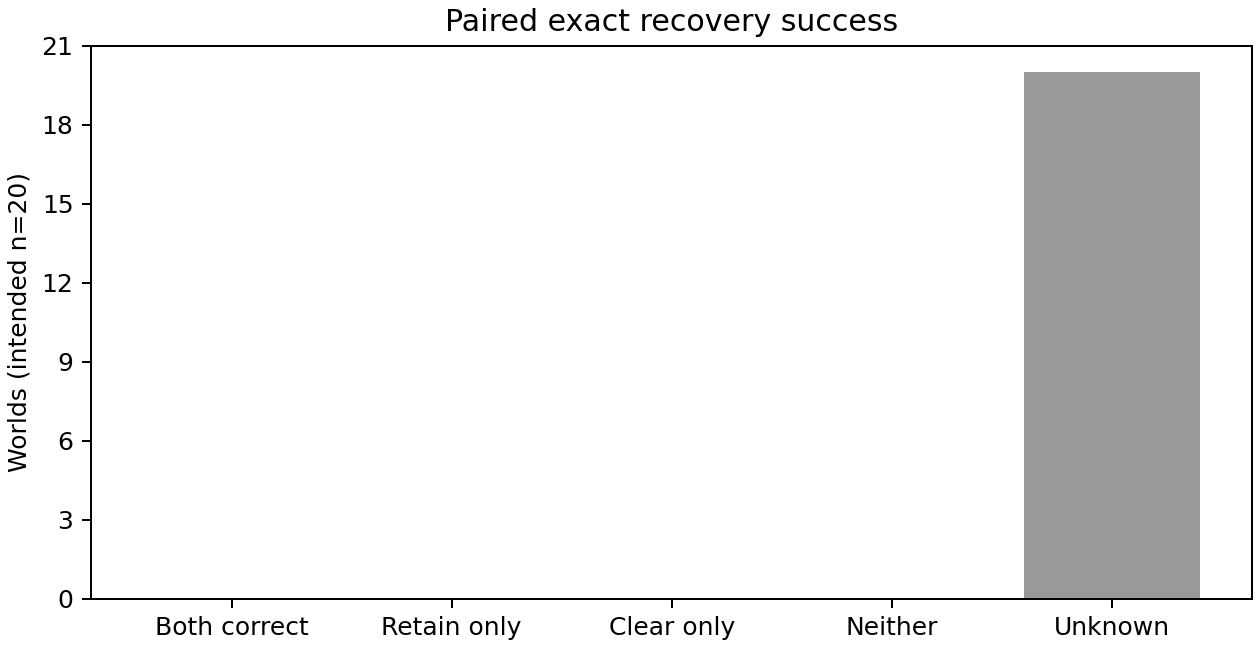

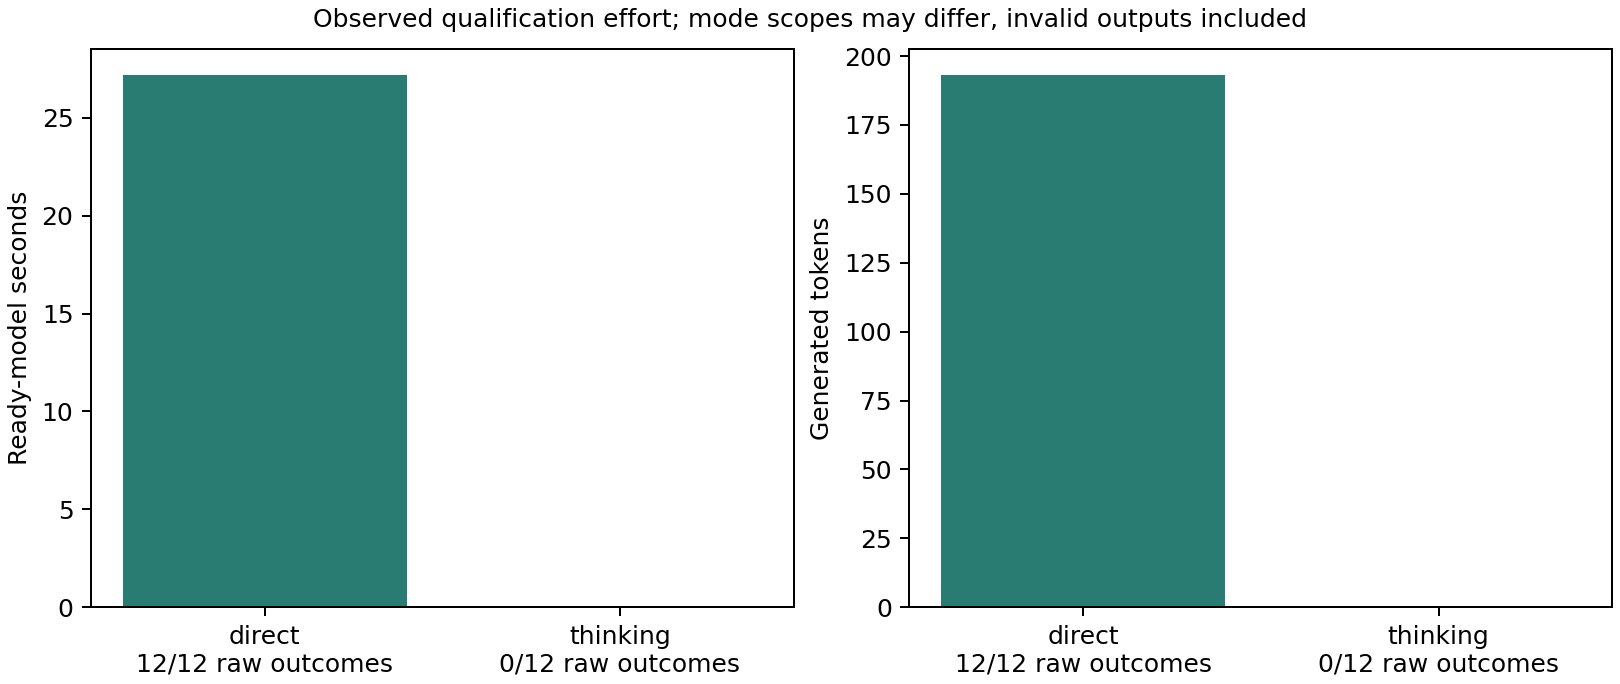

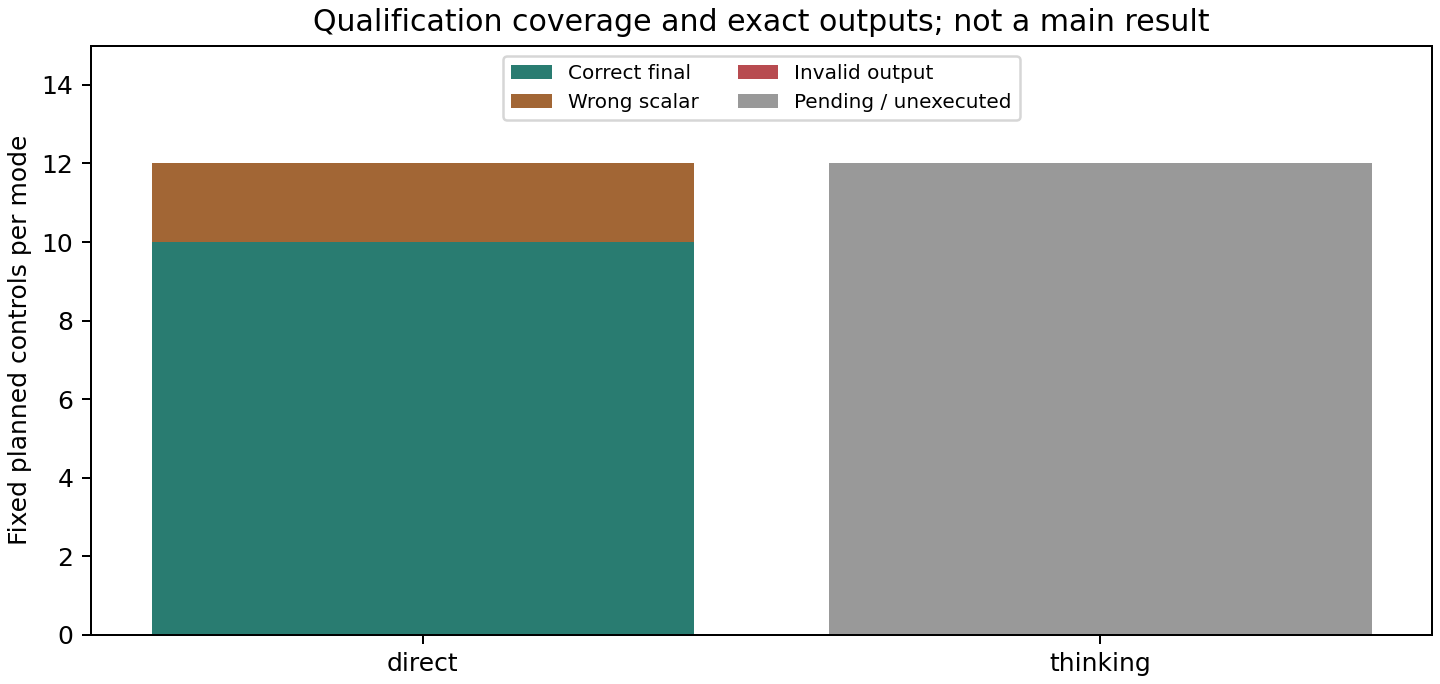

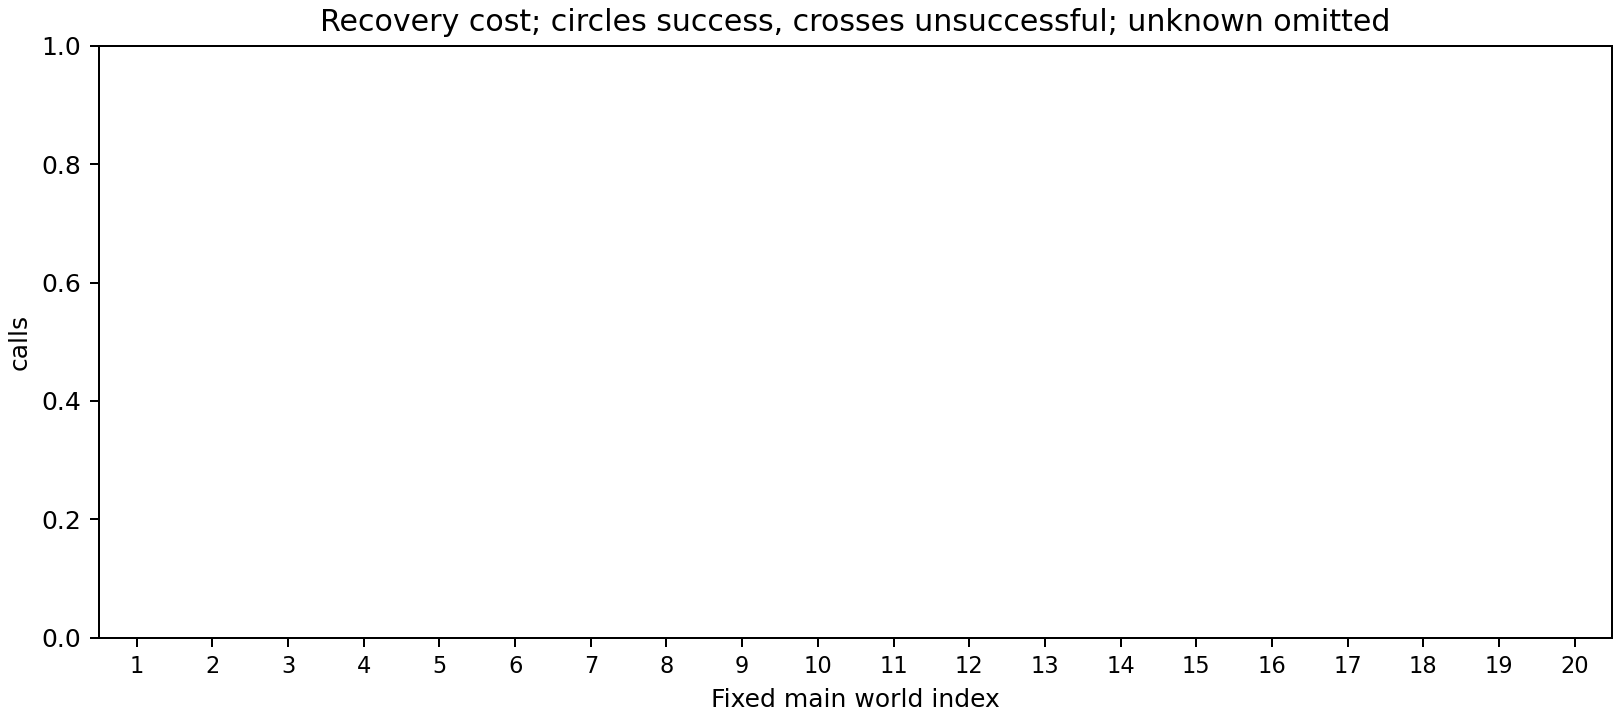

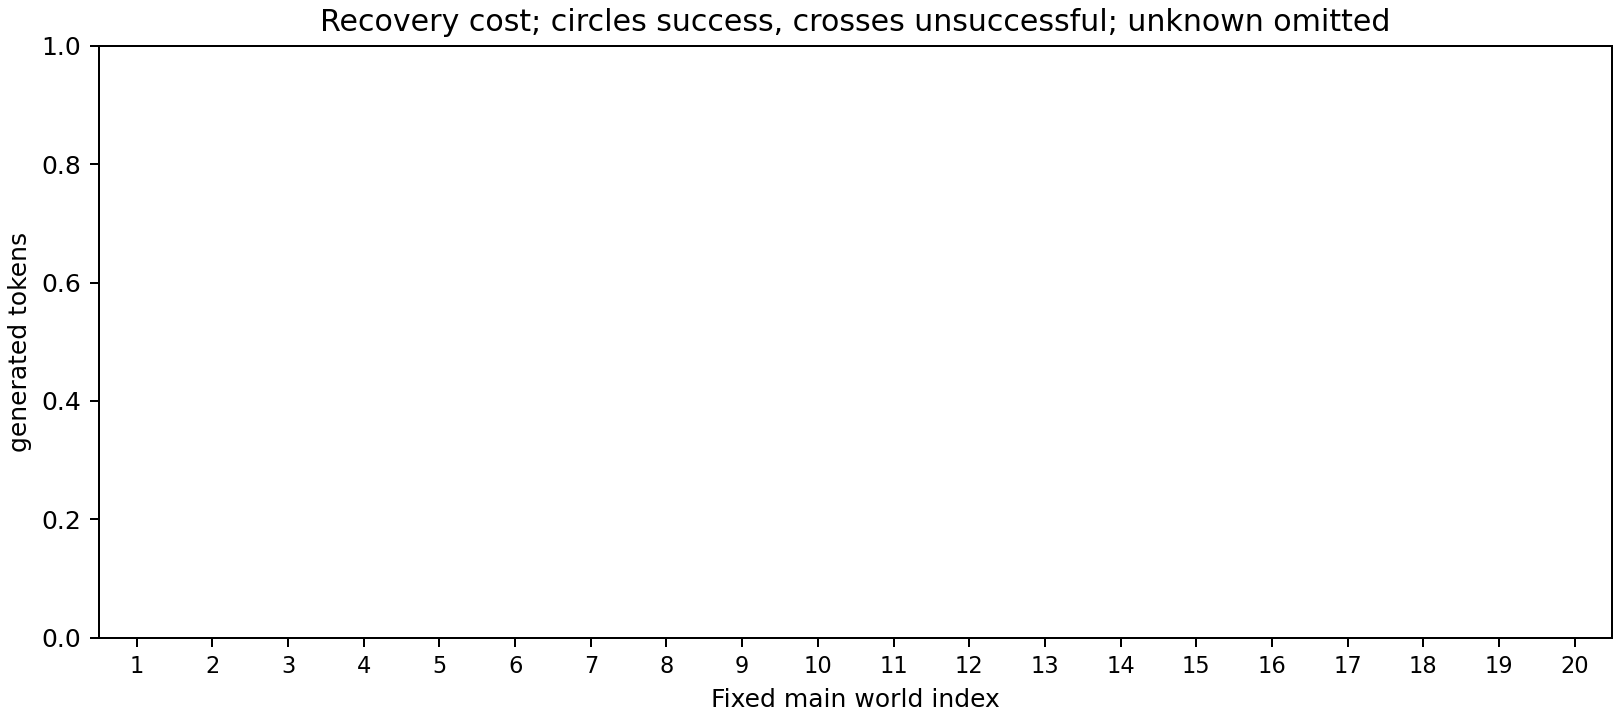

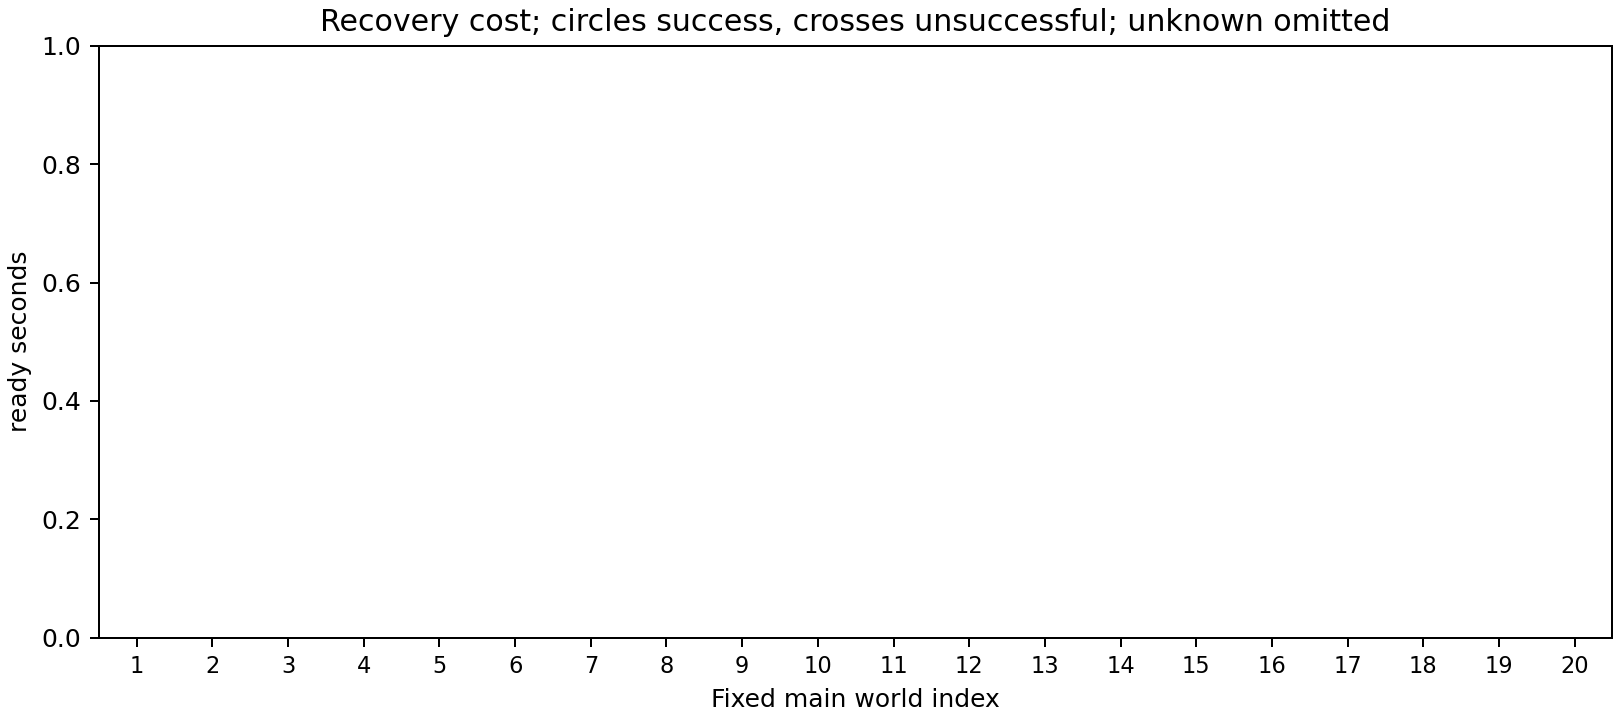

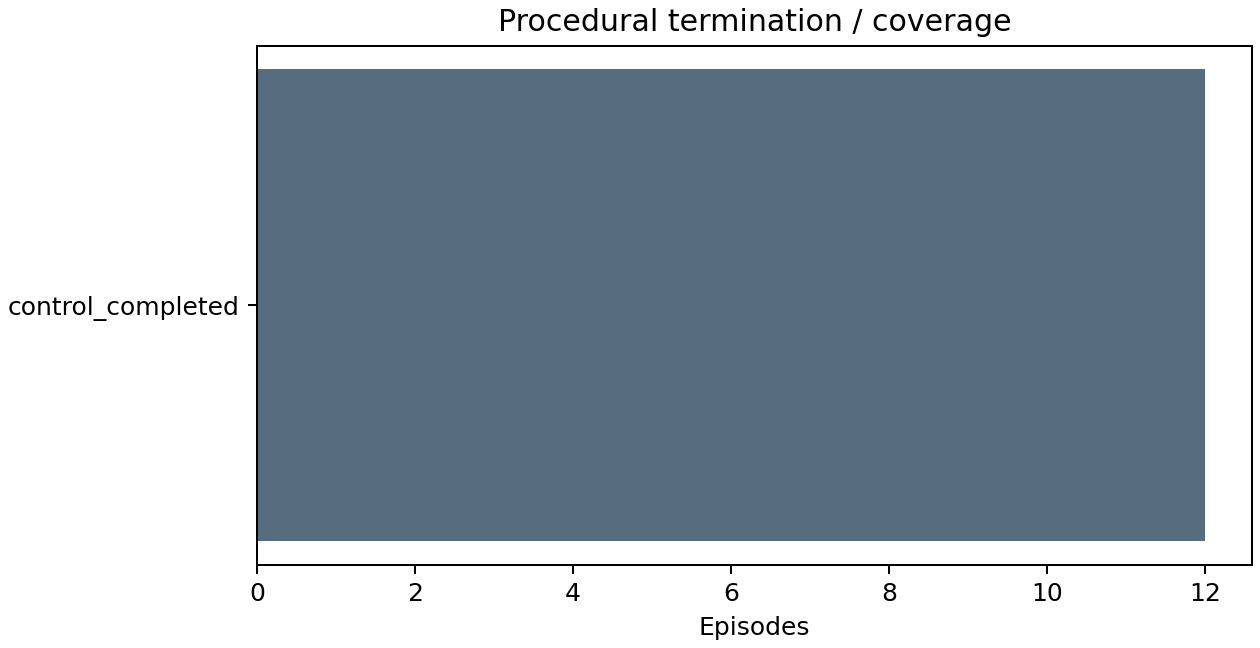

In [13]:
study.build_report();


## 14. Download and verify the checkpoint

Create the cumulative portable archive and verify read-only reconstruction. Download latest.zip and the executed notebook. Save this output without scheduling another Run All just to save it.


In [14]:
study.save_checkpoint(verify=True);


Checkpoint action/snapshot: 1,595,751 bytes; integrity passed
snapshot: complete · checkpoint /kaggle/working/i01-fresh-study/exports/latest.zip


Measurement,Recorded value
Boundary requested,operator-snapshot


Checkpoint: passed


Measurement,Recorded value
Integrity,passed
Attempts,20
Boundary,action/snapshot
Reconstruction,exact outcomes/costs/traces/gates match archived analysis
Model attempts,0


## After Run All

Expected on successful first attempts: **20 attempts here, zero prior charges**,
no thinking/pilot/main calls. Mathematical accuracy can be below 12/12 and is
reported without failing protocol qualification. Real protocol, resource and
isolation failures still stop execution and retain their evidence.

Download **/kaggle/working/i01-fresh-study/exports/latest.zip** and follow the
displayed links for reports, all conversations/raw replies, figures and receipts.
Every completed stage also publishes its cumulative checkpoint.

For the complete pilot/review/freeze/main workflow use the accompanying
**i01_course_research.ipynb**, whose research stages run individually. To keep
these loaded models, copy its pilot 1 and review cells into this notebook and
continue with the existing `study` object; do not repeat setup or loading.
Otherwise finish this controller before restoring the NEW checkpoint in the
research notebook, using its matching source and actual tail/exit evidence.
Newly loaded replicas need the separately charged two-probe reload validation.

Support commands (copy only the needed command into a new cell):

    study.show_status();
    study.inspect_qualification(mode="direct");
    study.inspect(audit_limit=None);  # Every raw call, no display limit.
    study.links(all_files=True);
    study.pause();  # Wait for an admitted call to settle before checkpoint/close.
    study.save_checkpoint(verify=True);
    study.record_state_review("Actual trace-based findings");  # Only if A/B/A needs review.
    study.configure_session(remaining_minutes=ACTUAL_CURRENT_MINUTES,
        evidence="Actual fresh provider observation", refresh=True);
    study.finish_session();  # Then stop Kaggle through its UI to release resources.

Do not replace failed gates, invent session facts or start another study to
bypass an error. Correct the demonstrated infrastructure error and resume its
saved scope. Wrong/malformed/truncated recorded model outcomes never retry.
